In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
data = {
    "hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "score": [35, 40, 50, 55, 60, 65, 70, 80, 85, 95]
}

df = pd.DataFrame(data)

df.head()

,hours,score
0,1,35
1,2,40
2,3,50
3,4,55
4,5,60


In [4]:
print(df.info())

print(df.describe())

print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   hours   10 non-null     int64
 1   score   10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes
None
          hours      score
count  10.00000  10.000000
mean    5.50000  63.500000
std     3.02765  19.443651
min     1.00000  35.000000
25%     3.25000  51.250000
50%     5.50000  62.500000
75%     7.75000  77.500000
max    10.00000  95.000000
hours    0
score    0
dtype: int64


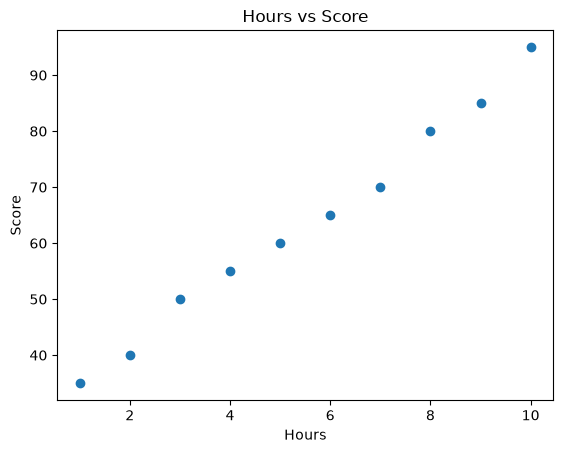

In [5]:
plt.scatter(df["hours"], df["score"])

plt.xlabel("Hours")
plt.ylabel("Score")
plt.title("Hours vs Score")

plt.show()

In [6]:
X = df[["hours"]]
y = df["score"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8, 1)
X_test: (2, 1)
y_train: (8,)
y_test: (2,)


In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[6.38]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,28.66
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [8]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_)

Intercept: 28.663793103448278
Coefficient: [6.37931034]


In [9]:
hours = 5

prediction = model.intercept_ + model.coef_[0] * hours

print(prediction)

60.560344827586206


In [10]:
model.predict(pd.DataFrame({"hours": [5]}))

array([60.56034483])

In [11]:
y_pred = model.predict(X_test)

print("Actual:")
print(y_test.values)

print("Predicted:")
print(y_pred)

Actual:
[85 40]
Predicted:
[86.07758621 41.42241379]
